In [192]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [193]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [194]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [195]:
df.shape

(2443651, 9)

In [196]:
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [197]:
df.select_dtypes("str").columns

Index(['asin', 'title', 'category'], dtype='str')

In [198]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='str')

In [199]:
df.select_dtypes("bool").columns

Index(['isBestSeller'], dtype='str')

In [200]:
len(df.columns) == (
    len(df.select_dtypes(include=['object', 'string']).columns)
    + len(df.select_dtypes(include=['number']).columns)
    + len(df.select_dtypes(include=['bool']).columns)
)


True

In [201]:
df.describe(include=['number']) # yo prefiero esta con 'numbers' asi me acuerdo

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [202]:
df.describe(include=['object','str'])


,asin,title,category
count,2443651,2443651,2443651
unique,2222742,2077591,296
top,B0884G1PZ5,OYhmc Portable Pedal Exerc,Sports & Outdoors
freq,7,723,836265


In [203]:
df.describe(include=['bool'])

,isBestSeller
count,2443651
unique,2
top,False
freq,2435671


In [204]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [205]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

---

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [206]:
frequency_table = df['category'].value_counts()
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\ernes\AppData\Local\Temp\ipykernel_26424\1446119025.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.index, y=top10.values, palette="Set3");


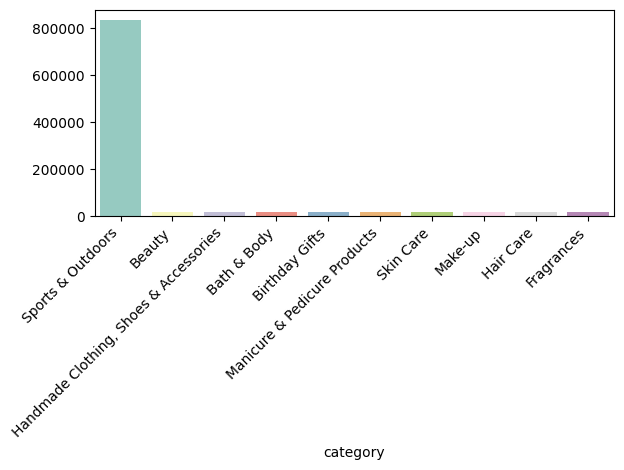

In [207]:

top10 = frequency_table.head(10)

sns.barplot(x=top10.index, y=top10.values, palette="Set3");
plt.xticks(rotation=45, ha='right') # esto lo busque para que se viesen las etiquetas
plt.tight_layout()
plt.show()

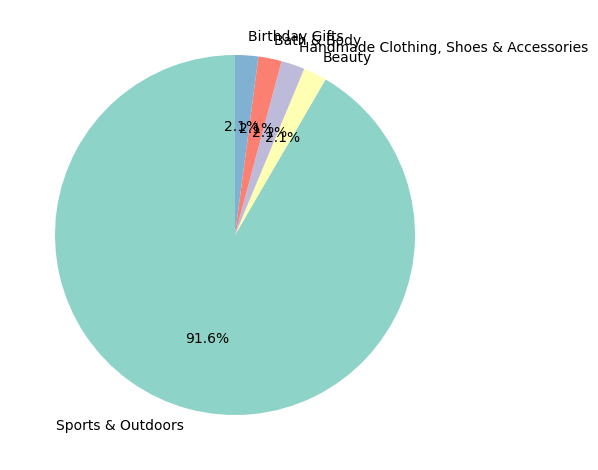

In [208]:
df['category'].value_counts().head(5).plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))
plt.xticks(rotation=30, ha='right') # esto lo busque para que se viesen las etiquetas
plt.tight_layout()
plt.show()

---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?



In [209]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [210]:
df['price'].dtype

dtype('float64')

In [211]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0] # da una tupla asi que saco asi el valor

print(f"mean_price = {round(float(mean_price),2)}")
print(f"median_price = {round(float(median_price),2)}")
print(f"mode_price = {round(float(mode_price),2)}")

mean_price = 89.24
median_price = 19.09
mode_price = 9.99


El precio promedio de los productos es el 'mean' = 89.24
El precio más común es el 'mode' = 9.99
Los productos suelen ser baratos, pero hay algunos carisimos que hacen que le media suba muchisimo

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?



In [212]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

print(f"variance_price = {round(float(variance_price),2)}")
print(f"std_dev_price = {round(float(std_dev_price),2)}")
print(f"min_price = {round(float(min_price),2)}")
print(f"max_price = {round(float(max_price),2)}")
print(f"range_price = {round(float(range_price),2)}")
print(f"quantiles_price = \n{quantiles_price}")

variance_price = 119445.49
std_dev_price = 345.61
min_price = 0.0
max_price = 100000.0
range_price = 100000.0
quantiles_price = 
0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64


Teniamos   
mean_price = 89.24
median_price = 19.09
mode_price = 9.99

La varianza es muy alta por que hay outliers enormes, pero recordar que es un valor al cuadrado asi que mejor ver la  
desviacion estandar.

Como hay outliers tan grandes la media no tiene mucha fiabilidad .

Si comparamos la desviacion estandar con la mediana sigue saliendo una desviacion altisima de 345 euros sobre 20

El rango es enorme ...normal si el maximo es 100000 y hay objetos de 20-20 euros, pero es que ademas  hay articulos a 0 Euros.. o son regalos o esta sin meter el precio o mal transformados

Los cuantiles nos dicen que les objetos son por lo general baratos ya que el 75 % de ellos no llegan a 50 euros.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

Vimos antes que la mayoria de precios caen entre 20 y 46 euros.

<Axes: xlabel='price', ylabel='Count'>

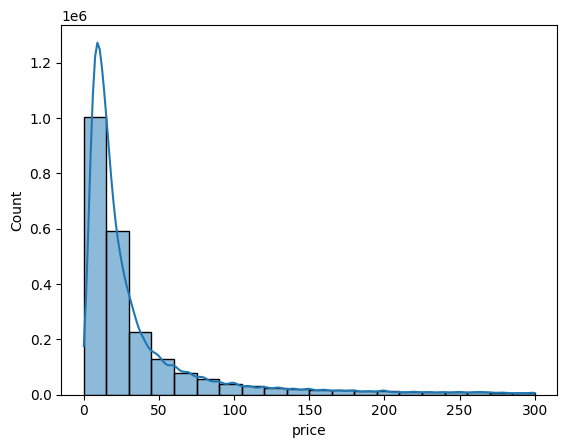

In [213]:
sns.histplot(df[df['price'] < 300]['price'], bins=20, kde=True)

<Axes: ylabel='price'>

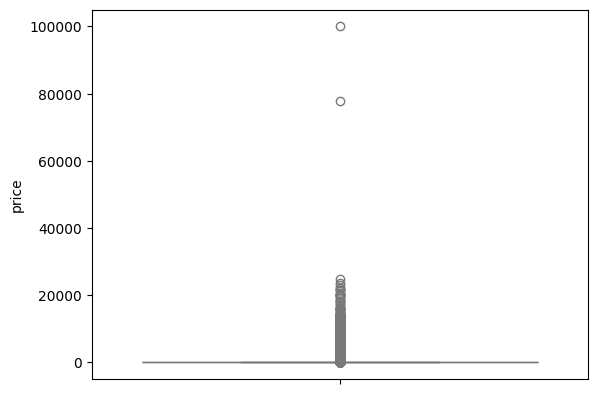

In [214]:
sns.boxplot(data = df['price'], color="lightblue")

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?


1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [215]:
df.tail()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing
2443650,2828593,B08P3W9B3T,RIDEX CJ223 Motorcycle Motorbike Jacket Armour...,4.5,34,53.99,False,0,Motorbike Clothing


In [216]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0] # da una tupla asi que saco asi el valor

print(f"mean_rating = {float(mean_rating)}")
print(f"median_rating = {float(median_rating)}")
print(f"mode_rating = {(float(mode_rating))}")


mean_rating = 2.152836472966066
median_rating = 0.0
mode_rating = 0.0


In [217]:
df['stars'].value_counts()


stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

Hay muchos 0 que rompen hasta la mediana , que mas de la mitad pongan 0 es o que es malisima Amazon a hay un fallo de pasar valores o que toma filas que no has sido valoradas que es lo mas probable y da 0 por defecto


In [218]:
df_no_zeros = df[df['stars'] != 0]
mean_rating = df_no_zeros['stars'].mean()
median_rating = df_no_zeros['stars'].median()
mode_rating = df_no_zeros['stars'].mode()[0] # da una tupla asi que saco asi el valor

print(f"mean_rating = {float(mean_rating)}")
print(f"median_rating = {float(median_rating)}")
print(f"mode_rating = {(float(mode_rating))}")


mean_rating = 4.319160762226911
median_rating = 4.4
mode_rating = 4.5


In [219]:
df['stars'].max()

np.float64(5.0)

Pues con estos resultados si suponemos que la puntion 5.0 es la maximala puntuan muy pero que muy bien


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [220]:
df_no_zeros = df[df['stars'] != 0]
variance_rating = df_no_zeros['stars'].var()
std_dev_rating = df_no_zeros['stars'].std()
min_rating = df_no_zeros['stars'].min()
max_rating = df_no_zeros['stars'].max()
range_rating = max_price - min_price
quantiles_rating = df_no_zeros['stars'].quantile([0.25, 0.5, 0.75])

print(f"variance_rating = {round(float(variance_rating),2)}")
print(f"std_dev_rating = {round(float(std_dev_rating),2)}")
print(f"min_rating = {round(float(min_rating),2)}")
print(f"max_rating = {round(float(max_rating),2)}")
print(f"range_rating = {round(float(range_rating),2)}")
print(f"quantiles_rating = \n{quantiles_rating}")

variance_rating = 0.31
std_dev_rating = 0.56
min_rating = 1.0
max_rating = 5.0
range_rating = 100000.0
quantiles_rating = 
0.25    4.1
0.50    4.4
0.75    4.6
Name: stars, dtype: float64


La desviacion standar es muy poca, medio punto, son muy constantes.
Los quantiles dan puntuaciones altisimas entre 4.1 y 4.6 la mayoria. 
Hay puntuaciones por debajo de 2 pero muy pocas




3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [223]:
df_no_zeros = df[df['stars'] != 0]

skewness_price = df_no_zeros['stars'].skew()
kurtosis_price = df_no_zeros['stars'].kurtosis()

skewness_price, kurtosis_price

(np.float64(-2.379568112212799), np.float64(9.78193769066435))

In [ ]:
La cola es hacia la izquierda y hay un pequeña numero de valores muy bajos y la mayoria de valores esta a la derecha.
EL kurtosis es altisimo >3 hay muchos valores extremos







4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.

<Axes: xlabel='stars', ylabel='Count'>

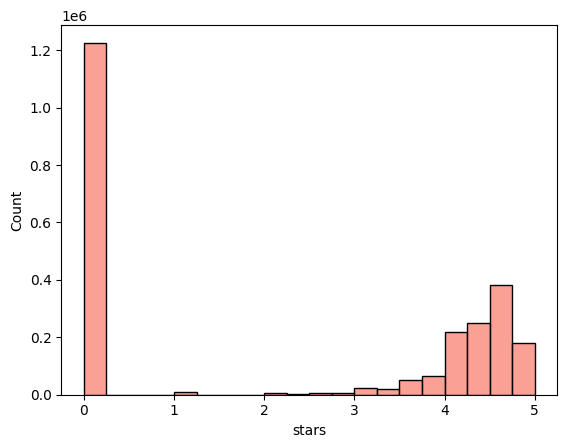

In [224]:
sns.histplot(df['stars'], kde=False, bins=20, color="salmon")

In [ ]:
A ver, si no filtramos nos sale que la mayoria de articulos estan sin valorar

<Axes: xlabel='stars', ylabel='Count'>

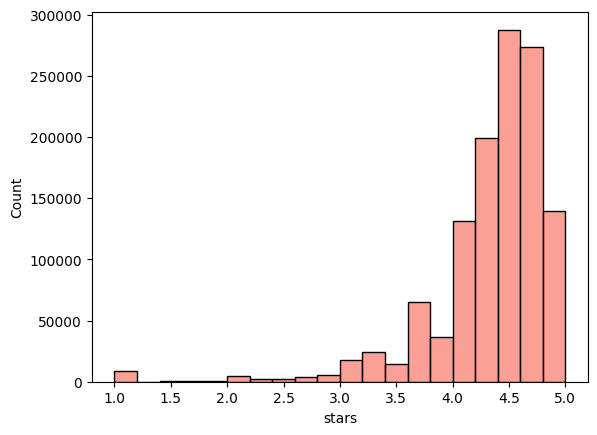

In [225]:
sns.histplot(df_no_zeros['stars'], kde=False, bins=20, color="salmon")

In [ ]:
Filtrando esa columna de no valorados vemos que entre 4,4, y 4,6 mas o menos estan la matoria